In [4]:
# !pip install torchmetrics

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
df = pd.read_csv("/content/drive/MyDrive/Datasets/adult.csv")
# df = pd.read_csv("adult.csv")

df.head(10)

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
5,34,Private,216864,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,3770,45,United-States,<=50K
6,38,Private,150601,10th,6,Separated,Adm-clerical,Unmarried,White,Male,0,3770,40,United-States,<=50K
7,74,State-gov,88638,Doctorate,16,Never-married,Prof-specialty,Other-relative,White,Female,0,3683,20,United-States,>50K
8,68,Federal-gov,422013,HS-grad,9,Divorced,Prof-specialty,Not-in-family,White,Female,0,3683,40,United-States,<=50K
9,41,Private,70037,Some-college,10,Never-married,Craft-repair,Unmarried,White,Male,0,3004,60,?,>50K


In [8]:
df.shape

(32561, 15)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [10]:
df.isna().sum().sum()

np.int64(0)

In [11]:
df.duplicated().sum()

np.int64(24)

In [12]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [13]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32537.000000,3.253700e+04,32537.000000,32537.000000,32537.000000,32537.000000
mean,38.585549,1.897808e+05,10.081815,1078.443741,87.368227,40.440329
std,13.637984,1.055565e+05,2.571633,7387.957424,403.101833,12.346889
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.369930e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [14]:
df.describe(exclude = "number")

,workclass,education,marital.status,occupation,relationship,race,sex,native.country,income
count,32537,32537,32537,32537,32537,32537,32537,32537,32537
unique,9,16,7,15,6,5,2,42,2
top,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K
freq,22673,10494,14970,4136,13187,27795,21775,29153,24698


### Cleaning :

In [15]:
from IPython.display import display

cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
  display(
    df[col].value_counts()
	)

,count
workclass,
Private,22673
Self-emp-not-inc,2540
Local-gov,2093
?,1836
State-gov,1298
Self-emp-inc,1116
Federal-gov,960
Without-pay,14
Never-worked,7


,count
education,
HS-grad,10494
Some-college,7282
Bachelors,5353
Masters,1722
Assoc-voc,1382
11th,1175
Assoc-acdm,1067
10th,933
7th-8th,645


,count
marital.status,
Married-civ-spouse,14970
Never-married,10667
Divorced,4441
Separated,1025
Widowed,993
Married-spouse-absent,418
Married-AF-spouse,23


,count
occupation,
Prof-specialty,4136
Craft-repair,4094
Exec-managerial,4065
Adm-clerical,3768
Sales,3650
Other-service,3291
Machine-op-inspct,2000
?,1843
Transport-moving,1597


,count
relationship,
Husband,13187
Not-in-family,8292
Own-child,5064
Unmarried,3445
Wife,1568
Other-relative,981


,count
race,
White,27795
Black,3122
Asian-Pac-Islander,1038
Amer-Indian-Eskimo,311
Other,271


,count
sex,
Male,21775
Female,10762


,count
native.country,
United-States,29153
Mexico,639
?,582
Philippines,198
Germany,137
Canada,121
Puerto-Rico,114
El-Salvador,106
India,100


,count
income,
<=50K,24698
>50K,7839


In [16]:
df[df["workclass"] == "?"]  # notice how when << workclass == ? >> , also : << occupation == ? >>

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
14,51,?,172175,Doctorate,16,Never-married,?,Not-in-family,White,Male,0,2824,40,United-States,>50K
24,61,?,135285,HS-grad,9,Married-civ-spouse,?,Husband,White,Male,0,2603,32,United-States,<=50K
44,71,?,100820,HS-grad,9,Married-civ-spouse,?,Husband,White,Male,0,2489,15,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32533,35,?,320084,Bachelors,13,Married-civ-spouse,?,Wife,White,Female,0,0,55,United-States,>50K
32534,30,?,33811,Bachelors,13,Never-married,?,Not-in-family,Asian-Pac-Islander,Female,0,0,99,United-States,<=50K
32541,71,?,287372,Doctorate,16,Married-civ-spouse,?,Husband,White,Male,0,0,10,United-States,>50K
32543,41,?,202822,HS-grad,9,Separated,?,Not-in-family,Black,Female,0,0,32,United-States,<=50K


In [17]:
cols_with_missing = ['workclass', 'occupation', 'native.country']
df[cols_with_missing] = df[cols_with_missing].replace('?', 'Unknown')

In [18]:
for col in cols_with_missing:
	display(df[col].value_counts(normalize=True, dropna=False))

,proportion
workclass,
Private,0.696837
Self-emp-not-inc,0.078065
Local-gov,0.064327
Unknown,0.056428
State-gov,0.039893
Self-emp-inc,0.034299
Federal-gov,0.029505
Without-pay,0.000430
Never-worked,0.000215


,proportion
occupation,
Prof-specialty,0.127117
Craft-repair,0.125826
Exec-managerial,0.124935
Adm-clerical,0.115807
Sales,0.112180
Other-service,0.101146
Machine-op-inspct,0.061468
Unknown,0.056643
Transport-moving,0.049083


,proportion
native.country,
United-States,0.895995
Mexico,0.019639
Unknown,0.017887
Philippines,0.006085
Germany,0.004211
Canada,0.003719
Puerto-Rico,0.003504
El-Salvador,0.003258
India,0.003073


# Feature Engineering :

In [19]:
# df['is_unemployed_or_unreported'] = (
#     (df['workclass'] == '?') & (df['occupation'] == '?')
# ).astype(int)

# df['country_is_missing'] = (df['native.country'] == '?').astype(int)

In [20]:
df["income"].value_counts(normalize=True)  # hmm , a Moderate imbalanced class , i'll keep it as it for the moment

,proportion
income,
<=50K,0.759074
>50K,0.240926


In [21]:
df["income"] = df["income"].map({'<=50K': 0, '>50K': 1})

In [22]:
df["income"].value_counts(normalize=True)

,proportion
income,
0,0.759074
1,0.240926


In [23]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,income
count,32537.000000,3.253700e+04,32537.000000,32537.000000,32537.000000,32537.000000,32537.000000
mean,38.585549,1.897808e+05,10.081815,1078.443741,87.368227,40.440329,0.240926
std,13.637984,1.055565e+05,2.571633,7387.957424,403.101833,12.346889,0.427652
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000,0.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000,0.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000,0.000000
75%,48.000000,2.369930e+05,12.000000,0.000000,0.000000,45.000000,0.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000,1.000000


<Axes: >

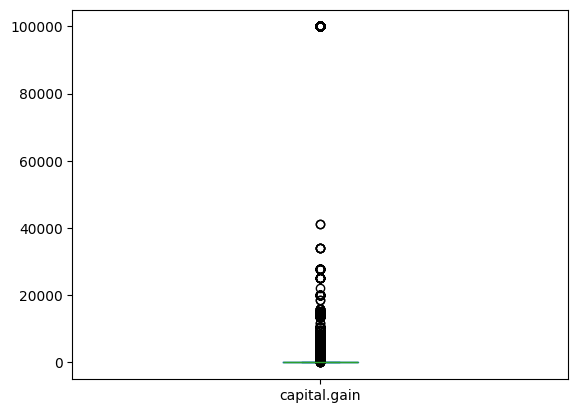

In [24]:
df["capital.gain"].plot(kind="box")  # the top points might look <<outliers>>, but ! these points are <<contributing>> strongly in <( >50k$ )> class ! 

In [25]:
df[df["capital.gain"] == 99999]["income"].value_counts() # w abbbbbbbbbbbbbbbb

,count
income,
1,159


### EDA :

array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'fnlwgt'}>,
        <Axes: title={'center': 'education.num'}>],
       [<Axes: title={'center': 'capital.gain'}>,
        <Axes: title={'center': 'capital.loss'}>,
        <Axes: title={'center': 'hours.per.week'}>],
       [<Axes: title={'center': 'income'}>, <Axes: >, <Axes: >]],
      dtype=object)

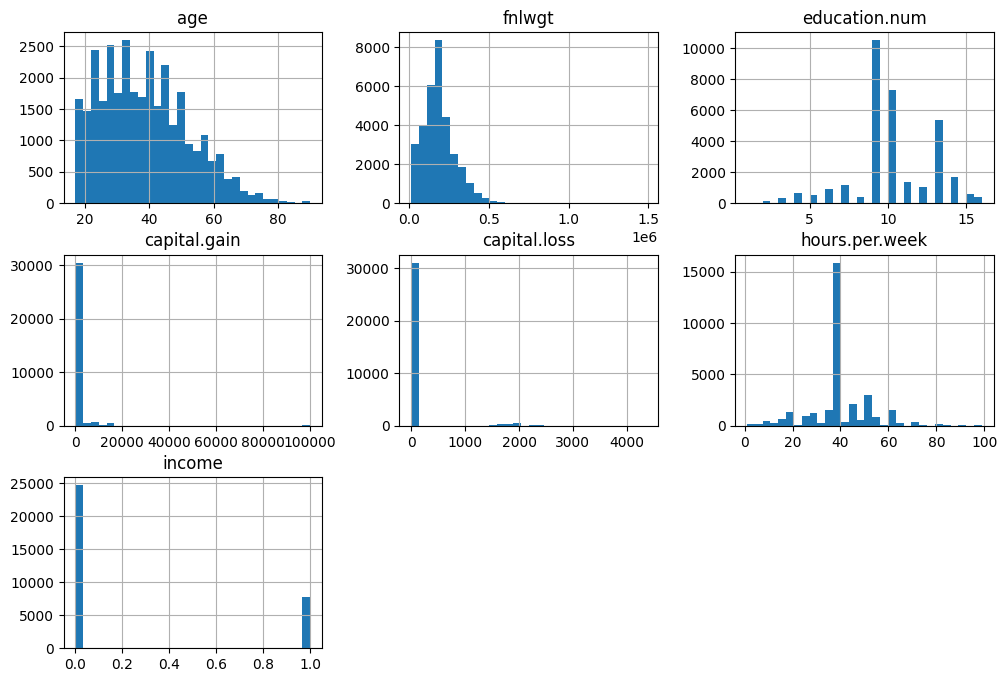

In [26]:
df.hist(bins=30, figsize=(12,8))

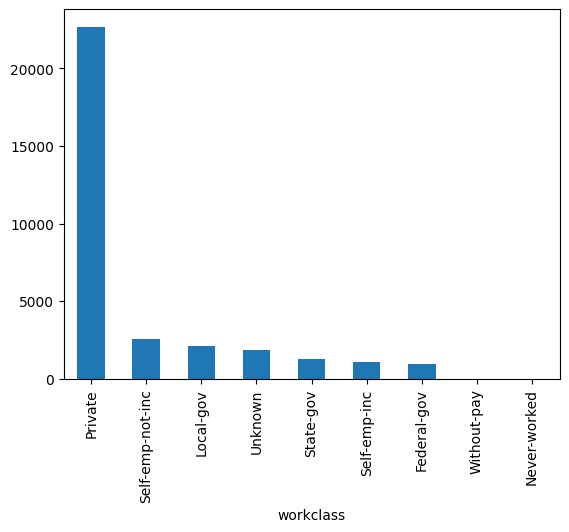

income,0,1,All
workclass,,,
Federal-gov,589,371,960
Local-gov,1476,617,2093
Never-worked,7,0,7
Private,17712,4961,22673
Self-emp-inc,494,622,1116
Self-emp-not-inc,1816,724,2540
State-gov,945,353,1298
Unknown,1645,191,1836
Without-pay,14,0,14


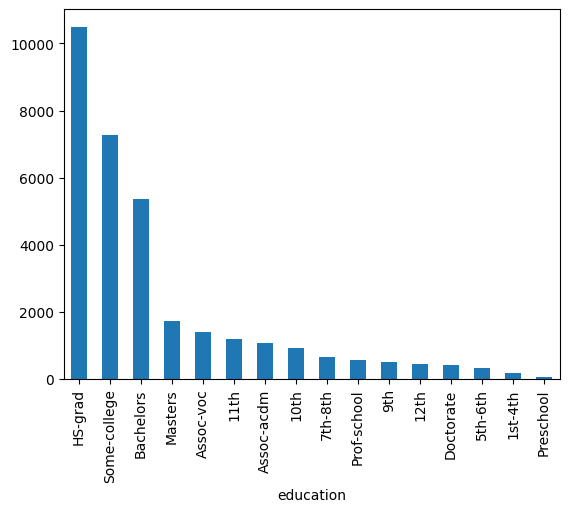

income,0,1,All
education,,,
10th,871,62,933
11th,1115,60,1175
12th,400,33,433
1st-4th,160,6,166
5th-6th,316,16,332
7th-8th,605,40,645
9th,487,27,514
Assoc-acdm,802,265,1067
Assoc-voc,1021,361,1382


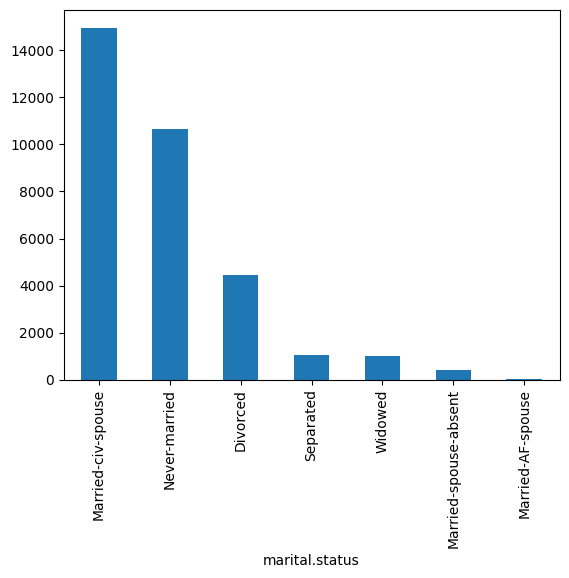

income,0,1,All
marital.status,,,
Divorced,3978,463,4441
Married-AF-spouse,13,10,23
Married-civ-spouse,8280,6690,14970
Married-spouse-absent,384,34,418
Never-married,10176,491,10667
Separated,959,66,1025
Widowed,908,85,993
All,24698,7839,32537


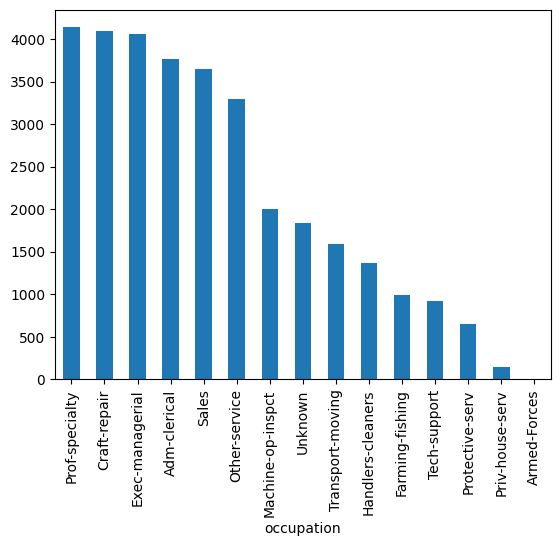

income,0,1,All
occupation,,,
Adm-clerical,3261,507,3768
Armed-Forces,8,1,9
Craft-repair,3165,929,4094
Exec-managerial,2097,1968,4065
Farming-fishing,877,115,992
Handlers-cleaners,1283,86,1369
Machine-op-inspct,1751,249,2000
Other-service,3154,137,3291
Priv-house-serv,146,1,147


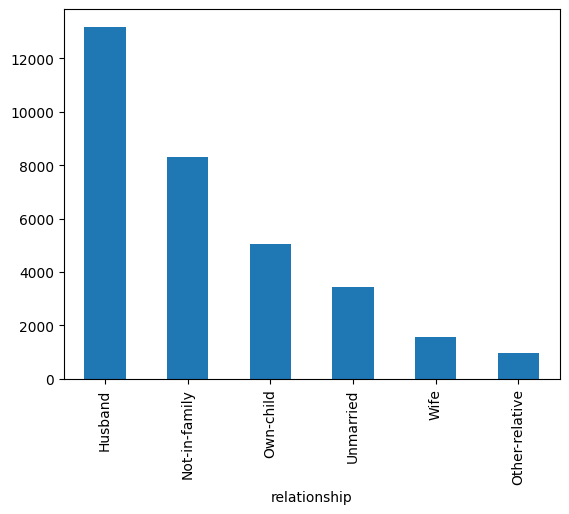

income,0,1,All
relationship,,,
Husband,7271,5916,13187
Not-in-family,7436,856,8292
Other-relative,944,37,981
Own-child,4997,67,5064
Unmarried,3227,218,3445
Wife,823,745,1568
All,24698,7839,32537


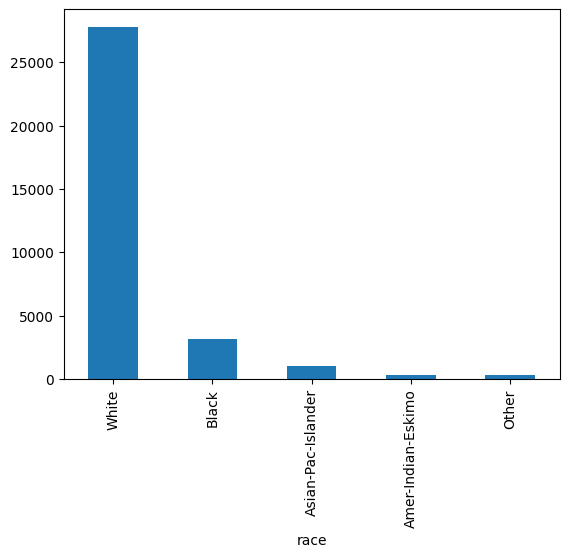

income,0,1,All
race,,,
Amer-Indian-Eskimo,275,36,311
Asian-Pac-Islander,762,276,1038
Black,2735,387,3122
Other,246,25,271
White,20680,7115,27795
All,24698,7839,32537


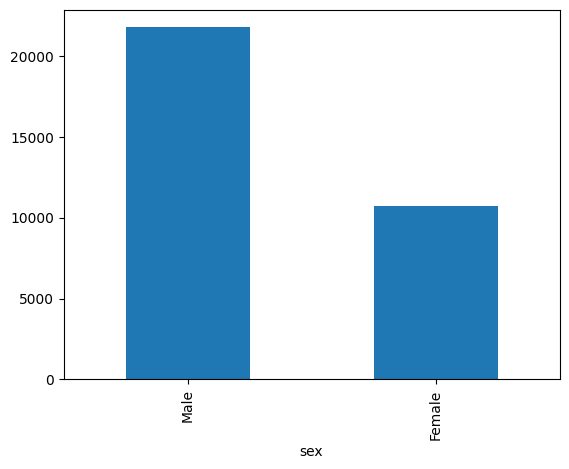

income,0,1,All
sex,,,
Female,9583,1179,10762
Male,15115,6660,21775
All,24698,7839,32537


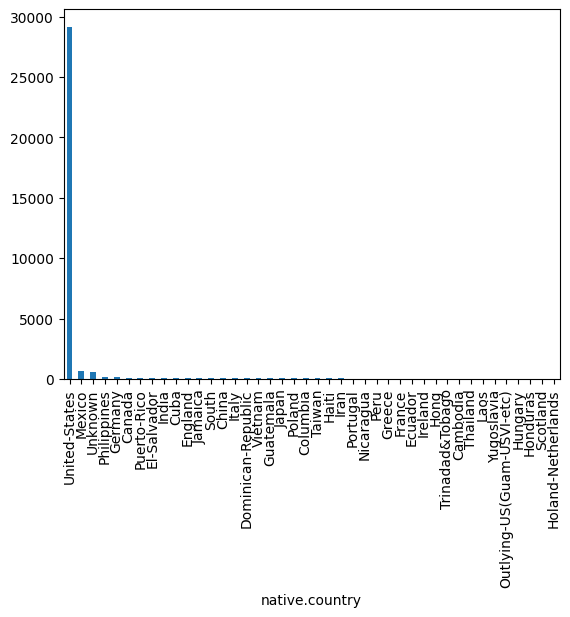

income,0,1,All
native.country,,,
Cambodia,12,7,19
Canada,82,39,121
China,55,20,75
Columbia,57,2,59
Cuba,70,25,95
Dominican-Republic,68,2,70
Ecuador,24,4,28
El-Salvador,97,9,106
England,60,30,90


In [27]:
from IPython.display import display

cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
  df[col].value_counts().plot(kind="bar")
  plt.show()
  display(
			pd.crosstab(
				df[col], 
				df['income'],
				# normalize=True,
				margins=True
			)
		)

In [28]:
pd.crosstab(
		df["sex"], 
		df['income'],
    normalize=True,
    margins=True
	)

income,0,1,All
sex,,,
Female,0.294526,0.036236,0.330762
Male,0.464548,0.204690,0.669238
All,0.759074,0.240926,1.000000


In [29]:
X = df.drop("income", axis=1)
y = df["income"].values

# Encoding :

In [30]:
X = pd.get_dummies(X, columns=cat_cols, drop_first=True)

# Scaling :

In [31]:
from sklearn.model_selection import train_test_split

X_train_nn, X_temp_nn, y_train_nn, y_temp_nn = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

X_val_nn, X_test_nn, y_val_nn, y_test_nn = train_test_split(
    X_temp_nn, y_temp_nn, test_size=0.5, stratify=y_temp_nn, random_state=42
)

In [32]:
from sklearn.preprocessing import StandardScaler

num_col = X.select_dtypes(include="number").columns

sc_nn = StandardScaler()
X_train_nn[num_col] = sc_nn.fit_transform(X_train_nn[num_col])
X_val_nn[num_col] = sc_nn.transform(X_val_nn[num_col])
X_test_nn[num_col] = sc_nn.transform(X_test_nn[num_col])

# Training :

In [33]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim

### Creating tensors :

In [34]:
for data in [X_train_nn, y_train_nn, X_val_nn, y_val_nn, X_test_nn, y_test_nn]:
  print(type(data))

<class 'pandas.core.frame.DataFrame'>
<class 'numpy.ndarray'>
<class 'pandas.core.frame.DataFrame'>
<class 'numpy.ndarray'>
<class 'pandas.core.frame.DataFrame'>
<class 'numpy.ndarray'>


In [35]:
X_train_nn, X_val_nn, X_test_nn = (
    X_train_nn.values,
    X_val_nn.values,
    X_test_nn.values,
)

In [36]:
for data in [X_train_nn, y_train_nn, X_val_nn, y_val_nn, X_test_nn, y_test_nn]:
  print(type(data))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [37]:
y_test_nn.dtype, y_val_nn.dtype, y_train_nn.dtype

(dtype('int64'), dtype('int64'), dtype('int64'))

In [38]:
X_train_nn  # Boolean one-hot values are converted to float32 before creating tensors.

array([[-1.2851185302858945, -0.47062742420114617, -0.031108965578278667,
        ..., False, False, False],
       [0.18326116479526297, 2.3065539552188254, 0.3576261592594639, ...,
        False, False, False],
       [-1.064861576023721, 0.49238360263664205, -0.4198440904160212,
        ..., False, False, False],
       ...,
       [1.2111269513520733, 1.4386830028499191, -0.031108965578278667,
        ..., False, False, False],
       [-1.2116995455318367, 0.45031640458183797, -0.4198440904160212,
        ..., False, False, False],
       [1.6516408598764205, -0.9176657981403743, -0.4198440904160212,
        ..., False, False, False]], dtype=object)

In [39]:
X_train_nn_clean = X_train_nn.astype(np.float32)
X_val_nn_clean = X_val_nn.astype(np.float32)
X_test_nn_clean = X_test_nn.astype(np.float32)

y_train_nn_clean = y_train_nn.astype(np.float32).reshape(-1, 1)
y_val_nn_clean = y_val_nn.astype(np.float32).reshape(-1, 1)
y_test_nn_clean = y_test_nn.astype(np.float32).reshape(-1, 1)

In [40]:
train_data = TensorDataset(torch.tensor(X_train_nn_clean), torch.tensor(y_train_nn_clean))
val_data = TensorDataset(torch.tensor(X_val_nn_clean), torch.tensor(y_val_nn_clean))
test_data = TensorDataset(torch.tensor(X_test_nn_clean), torch.tensor(y_test_nn_clean))

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64, shuffle=False)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

### model & optimizer & criterion :

In [41]:
model = nn.Sequential(
  nn.Linear(X_train_nn_clean.shape[1], 128),
  nn.ReLU(),
  nn.Dropout(0.2),

  nn.Linear(128, 64),
  nn.ReLU(),
  nn.Dropout(0.2),
  
  nn.Linear(64, 1),
  # nn.Sigmoid()   # i'll use BCEWithLogitsLoss, so no need for Sigmoid activaiton function
)

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.SGD(model.parameters(), lr=0.1, weight_decay=1e-4)

### training loop :

In [42]:
from torchmetrics.classification import BinaryAccuracy, BinaryConfusionMatrix, BinaryF1Score, BinaryRecall

num_epoch = 500
accuracy = BinaryAccuracy()
cm = BinaryConfusionMatrix()
recall = BinaryRecall()
f1 = BinaryF1Score()

train_loss_list = []
val_loss_list = []

best_recall = 0.0
best_f1 = 0.0
best_recall_path = None
best_f1_path = None

for epoch in range(num_epoch):

		# Training :
    
		model.train()
		train_loss = 0.0

		for X, y in train_loader:
				optimizer.zero_grad()

				logits = model(X)
				loss = criterion(logits, y)
				train_loss += loss.item()

				accuracy.update(logits, y)
				cm.update(logits, y)

				loss.backward()
				optimizer.step()

		train_loss /= len(train_loader)
		train_accuracy = accuracy.compute()

    # Validation :
		model.eval()
		val_loss = 0.0
		accuracy.reset()
		cm.reset()

		with torch.no_grad():
				for X, y in val_loader:
						logits = model(X)
						loss = criterion(logits, y)
						val_loss += loss.item()

						accuracy.update(logits, y)
						cm.update(logits, y)
						f1.update(logits, y)
						recall.update(logits, y)

		val_loss /= len(val_loader)
		val_accuracy = accuracy.compute()
		val_cm = cm.compute()
		val_f1 = f1.compute().item()
		val_recall = recall.compute().item()

		accuracy.reset()
		cm.reset()
		f1.reset()
		recall.reset()

		if val_recall > best_recall:
				best_recall = val_recall
				best_recall_path = f"/content/drive/MyDrive/Adult_Census-v2/best_recall_{epoch}.pth"
				torch.save(model.state_dict(), best_recall_path)

		if val_f1 > best_f1:
				best_f1 = val_f1
				best_f1_path = f"/content/drive/MyDrive/Adult_Census-v2/best_f1_{epoch}.pth"
				torch.save(model.state_dict(), best_f1_path)

		if epoch % 10 == 0:
				train_loss_list.append(train_loss)
				val_loss_list.append(val_loss)

				print(f"epoch : {epoch} train_loss : {train_loss:.4f} val_loss : {val_loss:.4f}")
				print(f"epoch : {epoch} train_accuracy : {train_accuracy:.4f} val_accuracy : {val_accuracy:.4f}")
				print(val_cm, "\n")

epoch : 0 train_loss : 0.3883 val_loss : 0.3289
epoch : 0 train_accuracy : 0.8154 val_accuracy : 0.8522
tensor([[2298,  172],
        [ 309,  475]]) 

epoch : 10 train_loss : 0.3044 val_loss : 0.3176
epoch : 10 train_accuracy : 0.8592 val_accuracy : 0.8494
tensor([[2283,  187],
        [ 303,  481]]) 

epoch : 20 train_loss : 0.2978 val_loss : 0.3165
epoch : 20 train_accuracy : 0.8630 val_accuracy : 0.8485
tensor([[2293,  177],
        [ 316,  468]]) 

epoch : 30 train_loss : 0.2926 val_loss : 0.3170
epoch : 30 train_accuracy : 0.8666 val_accuracy : 0.8546
tensor([[2307,  163],
        [ 310,  474]]) 

epoch : 40 train_loss : 0.2879 val_loss : 0.3167
epoch : 40 train_accuracy : 0.8681 val_accuracy : 0.8528
tensor([[2274,  196],
        [ 283,  501]]) 

epoch : 50 train_loss : 0.2839 val_loss : 0.3178
epoch : 50 train_accuracy : 0.8710 val_accuracy : 0.8491
tensor([[2253,  217],
        [ 274,  510]]) 

epoch : 60 train_loss : 0.2787 val_loss : 0.3206
epoch : 60 train_accuracy : 0.8720 

### best recall model :

In [51]:
model.load_state_dict(
  torch.load(
    "/content/drive/MyDrive/Adult_Census-v2/best_recall_74.pth",
    map_location="cpu",
    weights_only=True,
  )
)

model.eval()
f1 = BinaryF1Score()
recall = BinaryRecall()
accuracy = BinaryAccuracy()
cm = BinaryConfusionMatrix()

with torch.no_grad():
  for X_batch, y_batch in val_loader:
    logits = model(X_batch)
    f1.update(logits, y_batch)
    recall.update(logits, y_batch)
    accuracy.update(logits, y_batch)
    cm.update(logits, y_batch)

best_f1 = f1.compute()
best_recall = recall.compute()
best_accuracy = accuracy.compute()
best_cm = cm.compute()

print(f"best f1 : {best_f1:.4f} \nbest recall : {best_recall:.4f} \nbest accuracy : {best_accuracy:.4f}")
print(f"best_confusion_matrix : \n{best_cm}")

best f1 : 0.6855 
best recall : 0.7258 
best accuracy : 0.8396
best_confusion_matrix : 
tensor([[2163,  307],
        [ 215,  569]])


In [44]:
5

5

### best f1 model :

In [52]:
model.load_state_dict(
  torch.load(
    "/content/drive/MyDrive/Adult_Census-v2/best_f1_148.pth",
    map_location="cpu",
    weights_only=True,
  )
)

model.eval()
f1 = BinaryF1Score()
recall = BinaryRecall()
accuracy = BinaryAccuracy()
cm = BinaryConfusionMatrix()

with torch.no_grad():
  for X_batch, y_batch in val_loader:
    logits = model(X_batch)
    f1.update(logits, y_batch)
    recall.update(logits, y_batch)
    accuracy.update(logits, y_batch)
    cm.update(logits, y_batch)

best_f1 = f1.compute()
best_recall = recall.compute()
best_accuracy = accuracy.compute()
best_cm = cm.compute()

print(f"best f1 : {best_f1:.4f} \nbest recall : {best_recall:.4f} \nbest accuracy : {best_accuracy:.4f}")
print(f"best_confusion_matrix : \n{best_cm}")

best f1 : 0.6947 
best recall : 0.7258 
best accuracy : 0.8463
best_confusion_matrix : 
tensor([[2185,  285],
        [ 215,  569]])


### loss visualization :

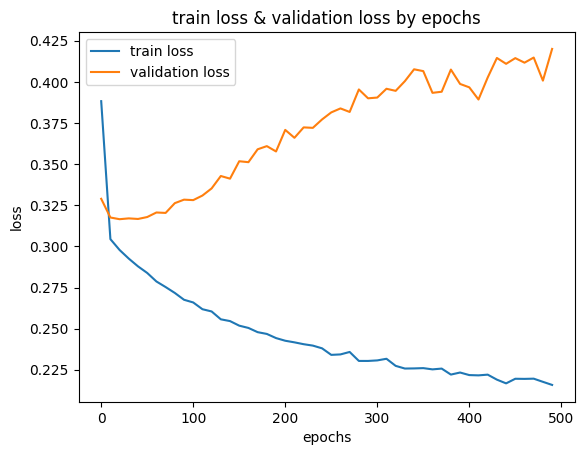

In [46]:
epoch_list = range(0, num_epoch, 10)

plt.plot(epoch_list, train_loss_list, label="train loss")
plt.plot(epoch_list, val_loss_list, label="validation loss")

plt.title("train loss & validation loss by epochs")
plt.xlabel("epochs")
plt.ylabel("loss")

plt.legend()

### Testing on Test Data :

In [57]:
model.load_state_dict(
  torch.load(
    "/content/drive/MyDrive/Adult_Census-v2/best_f1_148.pth",
    map_location="cpu",
    weights_only=True,
  )
)

# testing :
model.eval()
f1 = BinaryF1Score()
recall = BinaryRecall()
accuracy = BinaryAccuracy()
cm = BinaryConfusionMatrix()

with torch.no_grad():
  for X_batch, y_batch in test_loader:
    logits = model(X_batch)
    f1.update(logits, y_batch)
    recall.update(logits, y_batch)
    accuracy.update(logits, y_batch)
    cm.update(logits, y_batch)

best_f1 = f1.compute()
best_recall = recall.compute()
best_accuracy = accuracy.compute()
best_cm = cm.compute()

print(f"best f1 : {best_f1:.4f} \nbest recall : {best_recall:.4f} \nbest accuracy : {best_accuracy:.4f}")
print(f"best_confusion_matrix : \n{best_cm}")

best f1 : 0.6715 
best recall : 0.7105 
best accuracy : 0.8325
best_confusion_matrix : 
tensor([[2152,  318],
        [ 227,  557]])


# Random Forest :

In [48]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(class_weight="balanced",random_state=42)

rf.fit(X_train_nn, y_train_nn)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [49]:
y_preds = rf.predict(X_test_nn)

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print(f"accuracy : {accuracy_score(y_test_nn, y_preds)}\n confusion matrix : \n {confusion_matrix(y_test_nn, y_preds)}")
print(f"\n {classification_report(y_test_nn, y_preds)}")

accuracy : 0.8472649047326367
 confusion matrix : 
 [[2280  190]
 [ 307  477]]

               precision    recall  f1-score   support

           0       0.88      0.92      0.90      2470
           1       0.72      0.61      0.66       784

    accuracy                           0.85      3254
   macro avg       0.80      0.77      0.78      3254
weighted avg       0.84      0.85      0.84      3254



In [59]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 300],
    "max_depth": [None, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"],
    "criterion": ["gini", "entropy"],
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    verbose=2,
    n_jobs=-1,
)

grid_search.fit(X_train_nn, y_train_nn)

Fitting 5 folds for each of 64 candidates, totalling 320 fits


GridSearchCV(cv=5,
             estimator=RandomForestClassifier(class_weight='balanced',
                                              random_state=42),
             n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [None, 10],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 300]},
             scoring='f1', verbose=2)

In [60]:
best_rf = grid_search.best_estimator_

y_preds = best_rf.predict(X_test_nn)

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print(f"accuracy : {accuracy_score(y_test_nn, y_preds)}\n confusion matrix : \n {confusion_matrix(y_test_nn, y_preds)}")
print(f"\n {classification_report(y_test_nn, y_preds)}")

accuracy : 0.8315918869084205
 confusion matrix : 
 [[2079  391]
 [ 157  627]]

               precision    recall  f1-score   support

           0       0.93      0.84      0.88      2470
           1       0.62      0.80      0.70       784

    accuracy                           0.83      3254
   macro avg       0.77      0.82      0.79      3254
weighted avg       0.85      0.83      0.84      3254

